# 04 · Modelos clásicos sobre bolsa de palabras y TF-IDF

**Objetivo:** ampliar y ajustar el catálogo de modelos que trabajan sobre representaciones de bolsa de palabras (TF-IDF, selección de términos, SVD y rasgos hechos a mano), desde los lineales más simples hasta los no lineales, y compararlos con el mejor modelo actual: **V3 + SVM lineal (F1 macro 0.782 ± 0.016, `03_modelos`)**.

Se reutiliza la infraestructura de los notebooks anteriores: los mismos folds (`data/processed/folds.csv`), las mismas 6 variantes de preprocesamiento (D15), el mismo protocolo de decisión (umbral elegido en los otros folds y jerarquía HS=0 ⇒ TR=0, D13 y D17) y el mismo objeto de modelo (`modeling.TweetToxicClassifier`), que recibe **texto crudo**.

**Conceptos nuevos:**
- **Selección chi2:** el estadístico chi-cuadrado mide cuánto depende la presencia de un término de la etiqueta. `SelectKBest(chi2, k)` se queda con los *k* términos más dependientes. **Usa las etiquetas**, así que se calcula dentro de cada fold de entrenamiento y por separado para cada etiqueta.
- **SVD truncada:** comprime la matriz TF-IDF (miles de columnas dispersas) en unas pocas centenas de columnas densas, que combinan términos que aparecen juntos. No usa etiquetas.
- **NB-SVM:** un modelo lineal (aquí, regresión logística) entrenado sobre las features multiplicadas por la **razón log-count de Naive Bayes** de cada término: el logaritmo de cuánto más frecuente es el término en la clase positiva que en la negativa. Combina la robustez de NB con textos cortos y la flexibilidad del modelo lineal (Wang y Manning, 2012). La razón se calcula con las etiquetas del fold de entrenamiento.
- **Calibración:** transformar la puntuación de un clasificador en una probabilidad fiable (si dice 0.7, que acierte ~70% de las veces). Aquí se calibran con una sigmoide las SVM (lineal y RBF). El resto de modelos da puntuaciones en [0, 1] **no calibradas**; para la decisión no importa (el umbral se ajusta), pero sí para promediarlas en un ensamble.
- **CV anidada:** para elegir hiperparámetros sin inflar la métrica. En cada fold externo, una **validación cruzada interna de 3 folds**, hecha solo con los datos de entrenamiento de ese fold, elige la configuración; el fold externo **solo mide**. Si se eligiera la mejor configuración mirando las mismas cifras que se reportan, el resultado sería optimista: con 30 configuraciones, alguna gana por azar.

**Reglas:** nada preentrenado (spaCy solo para lemas y `Person=2`, sin vectores); todo lo que usa etiquetas (chi2, razones de NB-SVM, hiperparámetros, umbrales) se calcula dentro del fold de entrenamiento; los léxicos de los rasgos hechos a mano se definieron a mano en el `01_EDA` sin usar etiquetas.

## 1. Configuración

In [1]:
import json
import platform
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning

import handcrafted as hf
import modeling as md
import preprocessing as pp
from common import FIGURES_DIR, LABELS, PROCESSED_DIR, SEED, evaluate_oof, load_test, load_train, make_folds

warnings.filterwarnings("ignore", category=ConvergenceWarning)
np.random.seed(SEED)
sklearn.set_config(display="text")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
FAMILY_COLORS = {"lineal": "#2a78d6", "bayes": "#1baf7a", "vecinos": "#a3a29c", "kernel": "#4a3aa7",
                 "árboles": "#eb6834", "boosting": "#e34948"}
pd.set_option("display.width", 240)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.max_rows", 200)
N_JOBS = 5  # los 5 folds en paralelo; árboles y boosting usan además 2 hilos cada uno


def savefig(fig, name):
    fig.savefig(FIGURES_DIR / f"04_{name}.png", dpi=120, bbox_inches="tight")


import lightgbm
import xgboost

print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__} | "
      f"lightgbm {lightgbm.__version__} | SEED = {SEED}")
train = load_train()
test = load_test()
Y = train[LABELS].to_numpy()
folds = make_folds(train)
pp.load_lemma_cache(PROCESSED_DIR / "lemma_cache.parquet")
texts = train["text"]
print(f"Train: {len(train)} | Test: {len(test)} | folds: {folds.value_counts().sort_index().to_dict()}")

Python 3.14.6 | scikit-learn 1.9.1 | xgboost 3.4.1 | lightgbm 4.7.0 | SEED = 42
Train: 1731 | Test: 1154 | folds: {0: 347, 1: 346, 2: 346, 3: 346, 4: 346}


### Cómo se evalúa y se compara cada modelo

`run()` ejecuta la validación cruzada de una configuración (o la CV anidada, si recibe una rejilla de hiperparámetros) y, a continuación, entrena el modelo final con todo el train. De ese modelo final obtenemos su **tamaño** y sus **predicciones sobre el test**. El umbral del modelo final es el que maximiza el F1 sobre todas sus OOF (D17).

Para comparar con la referencia **V3 + SVM lineal** usamos la **diferencia pareada por fold** del F1 macro ajustado (mismos folds para todos):
- **empate** si |media de Δ| < desviación de Δ entre folds;
- **mejor** o **peor** si la diferencia supera esa desviación.

No se eligen ganadores dentro del empate.

**Progreso:** cada configuración imprime una línea al empezar (`[i/n] model_id (CV) ...`) y la completa al terminar con su F1 macro, lo que tardó y el tiempo total transcurrido. Las más lentas son la SVM RBF y las CV anidadas de los finalistas (sección 5), que pueden tardar varios minutos cada una. El notebook completo tarda del orden de una hora.

In [2]:
RESULTS = {}   # model_id -> resultado de la CV y modelo final
REF = "V3__linsvm"
T_START = time.perf_counter()


def _clock(seconds: float) -> str:
    m, s = divmod(int(seconds), 60)
    return f"{m:d}:{s:02d}"


def run(variant, classifier, features="tfidf", params=None, tag=None, grid=None, stage="cribado", step=None):
    """CV (o CV anidada si hay grid) + modelo final entrenado con todo el train. Cachea por model_id.

    Imprime una línea de progreso al empezar y otra al terminar (step = 'i/n' dentro de la sección)."""
    model_id = md.model_name(variant, classifier, features, tag)
    if model_id in RESULTS:
        if step:
            print(f"[{step}] {model_id}: ya calculado", flush=True)
        return RESULTS[model_id]
    start = time.perf_counter()
    kind = f"CV anidada, {len(grid)} configuraciones" if grid is not None else "CV"
    print(f"[{step or '·'}] {model_id} ({kind}) ...", end=" ", flush=True)
    if grid is None:
        model = md.TweetToxicClassifier(variant, classifier, features=features, clf_params=params or None)
        cv = md.cross_validate(model, texts, Y, folds, n_jobs=N_JOBS)
        final_params = params or None
    else:
        cv = md.nested_cross_validate(variant, classifier, features, grid, texts, Y, folds, n_jobs=N_JOBS)
        final_params, _ = md.select_params(variant, classifier, features, grid, texts, Y)  # misma CV interna, todo el train
    t0 = time.perf_counter()
    final = md.TweetToxicClassifier(variant, classifier, thresholds=md.best_thresholds(Y, cv["oof"]),
                                    features=features, clf_params=final_params).fit(texts, Y)
    RESULTS[model_id] = {"model_id": model_id, "variant": variant, "classifier": classifier, "features": features,
                         "tag": tag, "stage": stage, "grid": grid, "cv": cv, "model": final,
                         "final_fit_seconds": time.perf_counter() - t0, "size_mb": md.model_size_mb(final),
                         "test_proba": final.predict_proba(test["text"]), "test_pred": final.predict(test["text"])}
    f1 = cv["tuned"]["F1_macro"]
    print(f"F1 macro {f1.mean():.4f} ± {f1.std():.4f} | {time.perf_counter() - start:.1f} s "
          f"| total transcurrido {_clock(time.perf_counter() - T_START)}", flush=True)
    return RESULTS[model_id]


def verdict(d: pd.Series) -> str:
    if d.abs().max() == 0:
        return "referencia"
    if abs(d.mean()) < d.std():
        return "empate"
    return "mejor" if d.mean() > 0 else "peor"


def summarize(ids) -> pd.DataFrame:
    ref = RESULTS[REF]["cv"]["tuned"]["F1_macro"]
    rows = []
    for i in ids:
        r = RESULTS[i]
        t = r["cv"]["tuned"]
        d = t["F1_macro"] - ref
        rows.append({"model_id": i, "familia": md.FAMILIES[r["classifier"]], "variante": r["variant"],
                     **{lab: round(t[f"F1_{lab}"].mean(), 3) for lab in LABELS},
                     "macro": round(t["F1_macro"].mean(), 4), "desv.": round(t["F1_macro"].std(), 4),
                     "micro": round(t["F1_micro"].mean(), 4), "micro desv.": round(t["F1_micro"].std(), 4),
                     "Δ vs ref": round(d.mean(), 4), "Δ desv.": round(d.std(), 4), "folds mejor": int((d > 0).sum()),
                     "veredicto": verdict(d), "CV (s)": round(r["cv"]["fit_seconds"], 1),
                     "tamaño (MB)": round(r["size_mb"], 2)})
    return pd.DataFrame(rows).set_index("model_id").sort_values("macro", ascending=False)


ref = run("V3", "linsvm")
print(f"Referencia {REF}: F1 macro ajustado {ref['cv']['tuned']['F1_macro'].mean():.4f} ± "
      f"{ref['cv']['tuned']['F1_macro'].std():.4f} (03: 0.7817 ± 0.0160)")

[·] V3__linsvm (CV) ... 

F1 macro 0.7817 ± 0.0160 | 3.4 s | total transcurrido 0:03


Referencia V3__linsvm: F1 macro ajustado 0.7817 ± 0.0160 (03: 0.7817 ± 0.0160)


## 2. Catálogo de modelos y representaciones

| Familia | Modelo (`clave`) | Representación en el cribado | Configuración del cribado | ¿Probabilidad calibrada? |
|---|---|---|---|---|
| lineal | Regresión logística (`logreg`) | TF-IDF palabras + caracteres | C=1; L2 (liblinear), L1 y elasticnet 0.5 (saga) | No (balanceada) |
| lineal | SGDClassifier (`sgd`) | TF-IDF palabras + caracteres | pérdida `log_loss` y `modified_huber`, alpha=1e-4 | No |
| lineal | SVM lineal (`linsvm`) | TF-IDF palabras + caracteres | C=1 | **Sí** (sigmoide) |
| lineal | NB-SVM (`nbsvm`) | TF-IDF palabras + caracteres | C=1, alpha=1 | No |
| bayes | Multinomial, Bernoulli y Complement NB (`mnb`, `bnb`, `cnb`) | TF-IDF solo palabras | alpha=1 | No |
| vecinos | kNN coseno (`knn`), solo referencia | TF-IDF palabras + caracteres | k=15, ponderado por distancia | No |
| kernel | SVM RBF (`rbfsvm`) | TF-IDF palabras + caracteres (filas normalizadas) | C=1, gamma="scale" | **Sí** (sigmoide) |
| árboles | Random Forest y ExtraTrees (`rf`, `et`) | palabras → chi2 (k=500 o 2000) o SVD-300 | 300 árboles, `balanced_subsample` | No |
| boosting | XGBoost y LightGBM (`xgb`, `lgbm`) | palabras → chi2 (k=500 o 2000) o SVD-300 | 300 rondas, lr=0.05 | No |

**Por qué los árboles no reciben el TF-IDF completo.** Un árbol divide los datos por un rasgo cada vez. Con decenas de miles de columnas casi siempre a cero, la mayoría de divisiones posibles son inútiles, entrenar es lento y cada árbol solo ve unos pocos términos. Les damos dos entradas más compactas, ambas calculadas dentro del fold:
1. **chi2:** los *k* términos más asociados a cada etiqueta (*k* = 500 o 2000), que siguen siendo interpretables;
2. **SVD:** 300 componentes densas que resumen todo el vocabulario.

Siguiendo la pregunta P8, NB y los árboles usan **solo palabras** (sin n-gramas de caracteres): así se puede ver si la restauración y los lemas ayudan cuando no hay caracteres que absorban la fragmentación.

## 3. Cribado: todos los modelos sobre V1 (referencia) y V3 (mejor variante)

Cada configuración se evalúa con los mismos 5 folds, el umbral elegido en los otros folds y la jerarquía, igual que en el `03`. Ningún hiperparámetro se ajusta en esta fase: se usan valores por defecto razonables.

In [3]:
TREES = ["rf", "et", "xgb", "lgbm"]
SCREEN = [
    ("logreg", "tfidf", {}, None), ("logreg", "tfidf", {"l1_ratio": 1.0}, "l1"),
    ("logreg", "tfidf", {"l1_ratio": 0.5}, "en"),
    ("sgd", "tfidf", {"loss": "log_loss"}, "log"), ("sgd", "tfidf", {"loss": "modified_huber"}, "mhuber"),
    ("linsvm", "tfidf", {}, None), ("nbsvm", "tfidf", {}, None),
    ("mnb", "word", {}, None), ("bnb", "word", {}, None), ("cnb", "word", {}, None),
    ("knn", "tfidf", {}, None), ("rbfsvm", "tfidf", {}, None),
] + [(c, "word", {"select_k": k}, f"k{k}") for c in TREES for k in (500, 2000)] \
  + [(c, "word+svd", {}, None) for c in TREES]

t0 = time.perf_counter()
jobs = [(variant, cfg) for variant in ["V1", "V3"] for cfg in SCREEN]
for k, (variant, (clf, feats, params, tag)) in enumerate(jobs, 1):
    run(variant, clf, feats, params, tag, stage="cribado", step=f"{k}/{len(jobs)}")
screen_ids = [i for i, r in RESULTS.items() if r["stage"] == "cribado"]
print(f"{len(screen_ids)} configuraciones (con su modelo final) en {time.perf_counter() - t0:.0f} s")
screen = summarize(screen_ids)
display(screen[screen["variante"] == "V3"])

[1/48] V1__logreg (CV) ... 

F1 macro 0.7720 ± 0.0178 | 1.7 s | total transcurrido 0:05


[2/48] V1__logreg__l1 (CV) ... 

F1 macro 0.7366 ± 0.0182 | 5.0 s | total transcurrido 0:10


[3/48] V1__logreg__en (CV) ... 

...

F1 macro 0.7305 ± 0.0152 | 13.0 s | total transcurrido 4:42


[48/48] V3__lgbm__word+svd (CV) ... 

F1 macro 0.7328 ± 0.0254 | 11.8 s | total transcurrido 4:54


48 configuraciones (con su modelo final) en 291 s


,familia,variante,HS,TR,AG,macro,desv.,micro,micro desv.,Δ vs ref,Δ desv.,folds mejor,veredicto,CV (s),tamaño (MB)
model_id,,,,,,,,,,,,,,,
V3__linsvm,lineal,V3,0.776,0.823,0.746,0.7817,0.0160,0.7781,0.0161,0.0000,0.0000,0,referencia,1.7,2.05
V3__logreg,lineal,V3,0.780,0.804,0.739,0.7744,0.0196,0.7721,0.0198,-0.0073,0.0064,1,peor,0.4,0.99
V3__sgd__log,lineal,V3,0.767,0.818,0.736,0.7739,0.0191,0.7698,0.0181,-0.0078,0.0077,1,peor,0.3,0.99
V3__rbfsvm,kernel,V3,0.774,0.805,0.735,0.7714,0.0234,0.7688,0.0237,-0.0103,0.0099,0,peor,14.5,18.09
V3__nbsvm,lineal,V3,0.763,0.803,0.747,0.7709,0.0153,0.7678,0.0154,-0.0108,0.0077,0,peor,0.4,1.62
V3__et__word__k2000,árboles,V3,0.762,0.814,0.725,0.7670,0.0216,0.7635,0.0217,-0.0147,0.0086,0,peor,2.0,35.25
V3__sgd__mhuber,lineal,V3,0.744,0.807,0.724,0.7582,0.0229,0.7526,0.0209,-0.0235,0.0143,0,peor,0.3,0.93
V3__logreg__en,lineal,V3,0.744,0.801,0.728,0.7575,0.0132,0.7535,0.0134,-0.0242,0.0039,0,peor,0.6,0.37
V3__et__word__k500,árboles,V3,0.742,0.804,0.708,0.7512,0.0301,0.7468,0.0287,-0.0305,0.0169,0,peor,1.4,33.61


In [4]:
display(screen[screen["variante"] == "V1"])

,familia,variante,HS,TR,AG,macro,desv.,micro,micro desv.,Δ vs ref,Δ desv.,folds mejor,veredicto,CV (s),tamaño (MB)
model_id,,,,,,,,,,,,,,,
V1__linsvm,lineal,V1,0.769,0.816,0.742,0.7756,0.0223,0.7716,0.0212,-0.0061,0.0115,1,empate,0.5,2.08
V1__sgd__log,lineal,V1,0.760,0.812,0.752,0.7747,0.0214,0.7710,0.0208,-0.0070,0.0082,0,empate,0.3,1.00
V1__nbsvm,lineal,V1,0.762,0.808,0.750,0.7731,0.0127,0.7695,0.0116,-0.0086,0.0054,1,peor,0.3,1.65
V1__logreg,lineal,V1,0.772,0.803,0.741,0.7720,0.0178,0.7692,0.0172,-0.0097,0.0053,0,peor,0.3,1.00
V1__rbfsvm,kernel,V1,0.776,0.814,0.721,0.7702,0.0192,0.7666,0.0202,-0.0115,0.0052,0,peor,14.5,17.99
V1__sgd__mhuber,lineal,V1,0.757,0.798,0.729,0.7615,0.0194,0.7576,0.0186,-0.0202,0.0112,0,peor,0.2,0.93
V1__logreg__en,lineal,V1,0.743,0.803,0.723,0.7562,0.0151,0.7517,0.0147,-0.0255,0.0064,0,peor,0.5,0.37
V1__et__word__k2000,árboles,V1,0.757,0.802,0.707,0.7554,0.0179,0.7520,0.0157,-0.0263,0.0095,0,peor,1.7,35.31
V1__xgb__word__k2000,boosting,V1,0.733,0.794,0.724,0.7502,0.0170,0.7463,0.0159,-0.0315,0.0176,0,peor,1.3,1.08


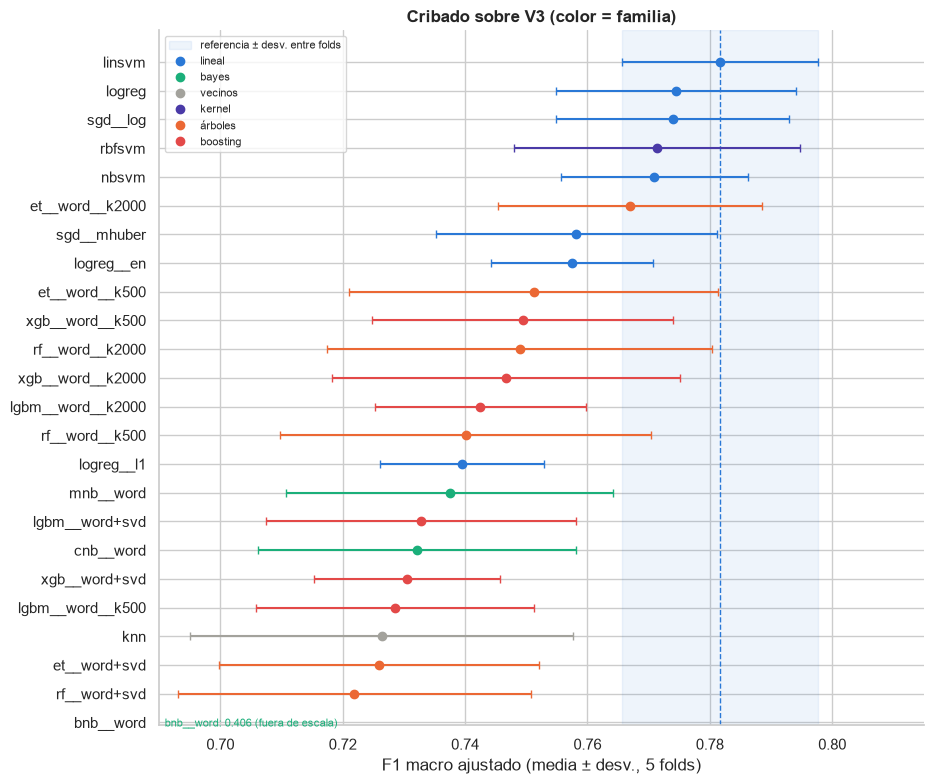

In [5]:
s3 = screen[screen["variante"] == "V3"].sort_values("macro")
fig, ax = plt.subplots(figsize=(9.5, 8))
y = np.arange(len(s3))
ref_mean = s3.loc[REF, "macro"]
ref_std = RESULTS[REF]["cv"]["tuned"]["F1_macro"].std()
ax.axvspan(ref_mean - ref_std, ref_mean + ref_std, color="#2a78d6", alpha=0.08, label="referencia ± desv. entre folds")
ax.axvline(ref_mean, color="#2a78d6", lw=1, ls="--")
XMIN = 0.69
for yi, (mid, row) in zip(y, s3.iterrows()):
    if row["macro"] < XMIN:  # fuera de escala (p. ej. Bernoulli NB): se indica con texto
        ax.annotate(f"{mid.replace('V3__', '')}: {row['macro']:.3f} (fuera de escala)", (XMIN, yi),
                    xytext=(4, -3), textcoords="offset points", fontsize=8, color=FAMILY_COLORS[row["familia"]])
        continue
    ax.errorbar(row["macro"], yi, xerr=row["desv."], fmt="o", color=FAMILY_COLORS[row["familia"]], capsize=3, ms=6)
ax.set_xlim(XMIN, 0.815)
ax.set(yticks=y, yticklabels=[m.replace("V3__", "") for m in s3.index], xlabel="F1 macro ajustado (media ± desv., 5 folds)",
       title="Cribado sobre V3 (color = familia)")
for fam, col in FAMILY_COLORS.items():
    ax.plot([], [], "o", color=col, label=fam)
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
savefig(fig, "screening")
plt.show()

**Interpretación del cribado** (sin ajustar hiperparámetros):
- **En V3 ningún modelo empata con la referencia (0.782 ± 0.016).** Los más cercanos son lineales: regresión logística L2 0.774, SGD `log_loss` 0.774, NB-SVM 0.771 y la SVM RBF 0.771. Las diferencias pareadas (−0.007 a −0.011) apenas superan su desviación, así que son "peores" por poco. En V1, la SVM lineal (0.776) y SGD `log_loss` (0.775) sí empatan con la referencia.
- **La regresión logística L1 y la elasticnet rinden mal con C=1** (0.740 y 0.758): esa regularización es demasiado fuerte para ellas. Por eso la rejilla de la CV anidada incluye C mayores.
- **Árboles y boosting quedan entre 0.015 y 0.06 por debajo.** El mejor es ExtraTrees con chi2-2000 (0.767). Con **chi2** rinden mejor que con **SVD** en los cuatro modelos (por ejemplo, RF 0.749 frente a 0.722 y LightGBM 0.743 frente a 0.733). Comprimir el vocabulario en 300 componentes densas pierde las palabras clave.
- **Naive Bayes solo con palabras:** Multinomial 0.738 y Complement 0.732. **Bernoulli NB colapsa (0.407; F1 de TR 0.115)**: con decenas de miles de rasgos binarios, sus probabilidades salen saturadas en 0 o 1 y ningún umbral las arregla.
- **kNN coseno** (solo referencia): 0.726.
- **Coste:** los lineales tardan menos de 2.5 s por CV y ocupan ≤ 2 MB. La SVM RBF tarda 16 s y ocupa 18 MB. Los bosques ocupan ≈20–48 MB.

## 4. Rasgos hechos a mano (D6 y D10)

`handcrafted.HandcraftedFeatures` calcula 39 rasgos **sobre el texto crudo**. Las minúsculas de V1+ destruyen la señal de mayúsculas, por eso el pipeline pasa también el texto original en una columna `raw`.

- **Superficiales (10):** longitud en caracteres y palabras, empieza con mención, nº de menciones, URL, hashtag, risa, proporción de mayúsculas y nº de `!` y `?` (los conteos en escala `log1p`).
- **Léxicos (29):**
  - un indicador por cada uno de los 19 grupos de insultos y los 5 de términos despectivos del `01` §6;
  - el número de grupos de insulto presentes y si hay algún término despectivo;
  - imperativo y número de formas de segunda persona (listas del `01` §5b);
  - `Person=2` de spaCy, cacheado.

Se escalan a [0, 1] con `MaxAbsScaler`. Así no dominan sobre el TF-IDF y siguen siendo no negativos (chi2 los admite). Los probamos de dos formas:
- **(a)** como columnas extra junto al TF-IDF en los modelos lineales;
- **(b)** como entrada adicional de los árboles y del boosting.

En ambos casos medimos la diferencia pareada frente al mismo modelo sin ellos.

In [6]:
H = hf.handcrafted_frame(train["text"])
by_class = pd.DataFrame({f"{lab}=1": H[train[lab] == 1].mean() for lab in ["HS", "TR"]} | {"todos": H.mean()})
display(by_class.loc[hf.SURFACE_NAMES + ["n_insult_groups", "any_slur", "imperative", "log_second_person", "person2_spacy"]].round(3).T)

,log_chars,log_words,starts_mention,log_mentions,has_url,has_hashtag,has_laugh,upper_ratio,log_excl,log_quest,n_insult_groups,any_slur,imperative,log_second_person,person2_spacy
HS=1,4.430,2.656,0.476,0.452,0.270,0.057,0.082,0.128,0.104,0.076,0.836,0.050,0.313,0.397,0.399
TR=1,4.251,2.490,0.649,0.569,0.166,0.019,0.112,0.147,0.090,0.046,1.106,0.019,0.455,0.531,0.511
todos,4.500,2.739,0.405,0.414,0.312,0.093,0.063,0.125,0.105,0.077,0.750,0.025,0.232,0.326,0.356


In [7]:
best_tree_input = {}
for c in TREES:  # mejor entrada de cada árbol según su F1 en V3
    cands = [i for i in screen_ids if RESULTS[i]["classifier"] == c and RESULTS[i]["variant"] == "V3"]
    best_tree_input[c] = max(cands, key=lambda i: RESULTS[i]["cv"]["tuned"]["F1_macro"].mean())
print("Mejor entrada por árbol (V3):", {c: (RESULTS[i]["features"], RESULTS[i]["tag"]) for c, i in best_tree_input.items()})

pairs = []
n_hand = 2 * (2 + len(best_tree_input))
k = 0
for variant in ["V1", "V3"]:
    for clf in ["linsvm", "logreg"]:
        k += 1
        base = run(variant, clf)
        plus = run(variant, clf, "tfidf+hand", tag=None, stage="rasgos", step=f"{k}/{n_hand}")
        pairs.append((base["model_id"], plus["model_id"]))
    for c, i in best_tree_input.items():
        k += 1
        r = RESULTS[i]
        base = run(variant, c, r["features"], RESULTS[i]["model"].clf_params, r["tag"])
        plus = run(variant, c, r["features"] + "+hand", RESULTS[i]["model"].clf_params, r["tag"], stage="rasgos",
                   step=f"{k}/{n_hand}")
        pairs.append((base["model_id"], plus["model_id"]))

rows = []
for base_id, plus_id in pairs:
    b, p = RESULTS[base_id]["cv"]["tuned"], RESULTS[plus_id]["cv"]["tuned"]
    d = p["F1_macro"] - b["F1_macro"]
    rows.append({"modelo con rasgos": plus_id, "sin rasgos": round(b["F1_macro"].mean(), 4),
                 "con rasgos": round(p["F1_macro"].mean(), 4), "Δ (media)": round(d.mean(), 4),
                 "Δ desv.": round(d.std(), 4), "folds mejor": int((d > 0).sum()),
                 **{f"Δ {lab}": round((p[f"F1_{lab}"] - b[f"F1_{lab}"]).mean(), 4) for lab in LABELS},
                 "¿aporta?": "sí" if d.mean() > d.std() else ("empeora" if -d.mean() > d.std() else "empate")})
hand_table = pd.DataFrame(rows).set_index("modelo con rasgos")
display(hand_table)

Mejor entrada por árbol (V3): {'rf': ('word', 'k2000'), 'et': ('word', 'k2000'), 'xgb': ('word', 'k500'), 'lgbm': ('word', 'k2000')}
[1/12] V1__linsvm__tfidf+hand (CV) ... 

F1 macro 0.7752 ± 0.0122 | 6.9 s | total transcurrido 5:03


[2/12] V1__logreg__tfidf+hand (CV) ... 

F1 macro 0.7661 ± 0.0229 | 2.0 s | total transcurrido 5:05


[3/12] V1__rf__word+hand__k2000 (CV) ... 

...

[11/12] V3__xgb__word+hand__k500 (CV) ... 

F1 macro 0.7563 ± 0.0152 | 3.1 s | total transcurrido 5:40


[12/12] V3__lgbm__word+hand__k2000 (CV) ... 

F1 macro 0.7455 ± 0.0249 | 3.5 s | total transcurrido 5:43


,sin rasgos,con rasgos,Δ (media),Δ desv.,folds mejor,Δ HS,Δ TR,Δ AG,¿aporta?
modelo con rasgos,,,,,,,,,
V1__linsvm__tfidf+hand,0.7756,0.7752,-0.0004,0.0164,2,0.0091,-0.0071,-0.0032,empate
V1__logreg__tfidf+hand,0.7720,0.7661,-0.0059,0.0128,1,-0.0107,-0.0010,-0.0060,empate
V1__rf__word+hand__k2000,0.7476,0.7480,0.0004,0.0161,2,0.0112,-0.0166,0.0065,empate
V1__et__word+hand__k2000,0.7554,0.7610,0.0056,0.0097,4,0.0047,-0.0010,0.0132,empate
V1__xgb__word+hand__k500,0.7409,0.7497,0.0088,0.0062,5,0.0165,-0.0116,0.0216,sí
V1__lgbm__word+hand__k2000,0.7423,0.7571,0.0149,0.0083,5,0.0148,0.0121,0.0176,sí
V3__linsvm__tfidf+hand,0.7817,0.7789,-0.0028,0.0083,1,0.0062,-0.0170,0.0025,empate
V3__logreg__tfidf+hand,0.7744,0.7674,-0.0070,0.0082,1,-0.0108,-0.0058,-0.0043,empate
V3__rf__word+hand__k2000,0.7489,0.7562,0.0073,0.0113,3,0.0178,-0.0047,0.0087,empate


**Interpretación:**
- **Las señales existen:** entre los TR=1 son mucho más frecuentes empezar con mención (64.9% frente a 40.5% en todo el train), el imperativo (45.5% frente a 23.2%), `Person=2` de spaCy (51.1% frente a 35.6%) y los grupos de insulto (1.11 de media frente a 0.75).
- **(a) En los modelos lineales no aportan:** SVM lineal −0.003 ± 0.008 (V3) y −0.000 ± 0.016 (V1); regresión logística −0.007 ± 0.008 (V3) y −0.006 ± 0.013 (V1). Todo es empate y ligeramente negativo: el TF-IDF ya contiene esas señales (`<USER>`, *cllate*, *eres*, los insultos).
- **(b) En árboles y boosting ayudan algo:** en V1 mejoran XGBoost (+0.009 ± 0.006) y LightGBM (+0.015 ± 0.008) en los 5 folds. En V3 todo queda en empate (−0.007 a +0.007). La ganancia viene sobre todo de AG (hasta +0.028) y de HS; TR suele bajar.

**Conclusión (D6 y D10):** los rasgos hechos a mano no se adoptan en los modelos lineales. En los árboles son opcionales, y aun con ellos los árboles siguen lejos de los lineales.

## 5. Finalistas: CV anidada en las 6 variantes

**Selección de finalistas:** los clasificadores cuyo mejor resultado del cribado en V3 **no es peor** que la referencia (empate o mejor), hasta un máximo de 5 y ordenados por F1 medio. Si hay menos de 4, se completan con los siguientes mejores. Cada finalista mantiene la representación con la que mejor funcionó en el cribado.

**Rejillas** (pequeñas, ≤ 15 configuraciones por modelo):

| Modelo | Rejilla |
|---|---|
| `logreg` | L2 con C ∈ {0.3, 1, 3, 10, 30}; elasticnet 0.5 con C ∈ {1, 3, 10}; L1 con C ∈ {3, 10} |
| `sgd` | pérdida ∈ {log_loss, modified_huber} × alpha ∈ {1e-5, 3e-5, 1e-4, 3e-4} |
| `linsvm` | C ∈ {0.03, 0.1, 0.3, 1, 3} |
| `nbsvm` | C ∈ {0.3, 1, 3, 10} × alpha ∈ {0.5, 1} |
| `rbfsvm` | C ∈ {0.3, 1, 3, 10} |
| `mnb`, `cnb` | alpha ∈ {0.03, 0.1, 0.3, 1} |
| `bnb` | alpha ∈ {0.1, 1} × k chi2 ∈ {todos, 2000, 5000} |
| `knn` | k ∈ {5, 15, 30, 50} |
| `rf`, `et` | k chi2 ∈ {500, 2000, 5000} × hojas mínimas ∈ {1, 3} × max_features ∈ {sqrt, 0.1} |
| `xgb` | k chi2 ∈ {500, 2000} × profundidad ∈ {3, 6} × lr ∈ {0.05, 0.1} |
| `lgbm` | k chi2 ∈ {500, 2000} × hojas ∈ {7, 15, 31} × lr ∈ {0.05, 0.1} |

(En los árboles con entrada SVD no hay k que elegir.) La CV interna elige la configuración por F1 macro con el umbral óptimo sobre sus propias OOF. Esa cifra interna es optimista, pero lo es igual para todas las configuraciones, y nunca se reporta. Lo que se reporta es el F1 del fold externo.

In [8]:
GRIDS = {
    "logreg": [{"C": c} for c in (0.3, 1.0, 3.0, 10.0, 30.0)] + [{"C": c, "l1_ratio": 0.5} for c in (1.0, 3.0, 10.0)]
              + [{"C": c, "l1_ratio": 1.0} for c in (3.0, 10.0)],
    "sgd": [{"loss": l, "alpha": a} for l in ("log_loss", "modified_huber") for a in (1e-5, 3e-5, 1e-4, 3e-4)],
    "linsvm": [{"C": c} for c in (0.03, 0.1, 0.3, 1.0, 3.0)],
    "nbsvm": [{"C": c, "alpha": a} for c in (0.3, 1.0, 3.0, 10.0) for a in (0.5, 1.0)],
    "rbfsvm": [{"C": c} for c in (0.3, 1.0, 3.0, 10.0)],
    "mnb": [{"alpha": a} for a in (0.03, 0.1, 0.3, 1.0)], "cnb": [{"alpha": a} for a in (0.03, 0.1, 0.3, 1.0)],
    "bnb": [{"alpha": a, "select_k": k} for a in (0.1, 1.0) for k in (None, 2000, 5000)],
    "knn": [{"n_neighbors": k} for k in (5, 15, 30, 50)],
    "rf": [{"select_k": k, "min_samples_leaf": m, "max_features": f} for k in (500, 2000, 5000) for m in (1, 3) for f in ("sqrt", 0.1)],
    "et": [{"select_k": k, "min_samples_leaf": m, "max_features": f} for k in (500, 2000, 5000) for m in (1, 3) for f in ("sqrt", 0.1)],
    "xgb": [{"select_k": k, "max_depth": d, "learning_rate": lr} for k in (500, 2000) for d in (3, 6) for lr in (0.05, 0.1)],
    "lgbm": [{"select_k": k, "num_leaves": n, "learning_rate": lr} for k in (500, 2000) for n in (7, 15, 31) for lr in (0.05, 0.1)],
}


def grid_for(classifier, features):
    grid = GRIDS[classifier]
    if "svd" in features.split("+"):  # con SVD no hay selección chi2
        grid = [dict(t) for t in {tuple(sorted((k, v) for k, v in g.items() if k != "select_k")) for g in grid}]
        grid = sorted(grid, key=lambda g: json.dumps(g, sort_keys=True))
    return grid


s3 = screen[screen["variante"] == "V3"].copy()
s3["clasificador"] = [RESULTS[i]["classifier"] for i in s3.index]
best_per_clf = s3.sort_values("macro", ascending=False).groupby("clasificador", sort=False).head(1)
eligible = best_per_clf[best_per_clf["veredicto"].isin(["referencia", "empate", "mejor"])]
finalists = list(eligible.index[:5])
for mid in best_per_clf.index:
    if len(finalists) >= 4:
        break
    if mid not in finalists:
        finalists.append(mid)
FINALISTS = [(RESULTS[i]["classifier"], RESULTS[i]["features"]) for i in finalists]
display(best_per_clf[["familia", "macro", "desv.", "Δ vs ref", "Δ desv.", "veredicto"]])
print("Finalistas (clasificador, representación):", FINALISTS)
print("Tamaño de rejilla:", {c: len(grid_for(c, f)) for c, f in FINALISTS})

,familia,macro,desv.,Δ vs ref,Δ desv.,veredicto
model_id,,,,,,
V3__linsvm,lineal,0.7817,0.0160,0.0000,0.0000,referencia
V3__logreg,lineal,0.7744,0.0196,-0.0073,0.0064,peor
V3__sgd__log,lineal,0.7739,0.0191,-0.0078,0.0077,peor
V3__rbfsvm,kernel,0.7714,0.0234,-0.0103,0.0099,peor
V3__nbsvm,lineal,0.7709,0.0153,-0.0108,0.0077,peor
V3__et__word__k2000,árboles,0.7670,0.0216,-0.0147,0.0086,peor
V3__xgb__word__k500,boosting,0.7494,0.0246,-0.0323,0.0170,peor
V3__rf__word__k2000,árboles,0.7489,0.0314,-0.0328,0.0193,peor
V3__lgbm__word__k2000,boosting,0.7425,0.0173,-0.0392,0.0102,peor


Finalistas (clasificador, representación): [('linsvm', 'tfidf'), ('logreg', 'tfidf'), ('sgd', 'tfidf'), ('rbfsvm', 'tfidf')]
Tamaño de rejilla: {'linsvm': 5, 'logreg': 10, 'sgd': 8, 'rbfsvm': 4}


In [9]:
t0 = time.perf_counter()
jobs = [(clf, feats, variant) for clf, feats in FINALISTS for variant in pp.VARIANTS]
for k, (clf, feats, variant) in enumerate(jobs, 1):
    run(variant, clf, feats, tag="nested", grid=grid_for(clf, feats), stage="finalista", step=f"{k}/{len(jobs)}")
nested_ids = [i for i, r in RESULTS.items() if r["stage"] == "finalista"]
print(f"{len(nested_ids)} CV anidadas en {time.perf_counter() - t0:.0f} s")
nested = summarize(nested_ids)
nested["clasificador"] = [RESULTS[i]["classifier"] for i in nested.index]
nested["hiperparámetros por fold"] = [" | ".join(json.dumps(p, sort_keys=True) for p in RESULTS[i]["cv"]["params_per_fold"])
                                      for i in nested.index]
nested["final (todo el train)"] = [json.dumps(RESULTS[i]["model"].clf_params, sort_keys=True) for i in nested.index]
display(nested.drop(columns=["hiperparámetros por fold"]))

[1/24] V0__linsvm__nested (CV anidada, 5 configuraciones) ... 

F1 macro 0.7641 ± 0.0087 | 7.4 s | total transcurrido 5:51


[2/24] V1__linsvm__nested (CV anidada, 5 configuraciones) ... 

F1 macro 0.7745 ± 0.0235 | 8.6 s | total transcurrido 5:59


[3/24] V2__linsvm__nested (CV anidada, 5 configuraciones) ... 

...

F1 macro 0.7845 ± 0.0242 | 257.7 s | total transcurrido 40:00


[24/24] V4__rbfsvm__nested (CV anidada, 4 configuraciones) ... 

F1 macro 0.7691 ± 0.0258 | 291.5 s | total transcurrido 44:52


24 CV anidadas en 2349 s


,familia,variante,HS,TR,AG,macro,desv.,micro,micro desv.,Δ vs ref,Δ desv.,folds mejor,veredicto,CV (s),tamaño (MB),clasificador,final (todo el train)
model_id,,,,,,,,,,,,,,,,,
V2__logreg__nested,lineal,V2,0.786,0.833,0.762,0.7937,0.0216,0.7897,0.0212,0.0120,0.0085,5,mejor,48.0,0.52,logreg,"{""C"": 10.0, ""l1_ratio"": 0.5}"
V4__logreg__nested,lineal,V4,0.783,0.831,0.755,0.7896,0.0240,0.7855,0.0247,0.0079,0.0134,4,empate,65.3,0.74,logreg,"{""C"": 10.0, ""l1_ratio"": 0.5}"
V2-alarg1__logreg__nested,lineal,V2 (alarg.=1),0.782,0.832,0.755,0.7895,0.0241,0.7852,0.0232,0.0078,0.0108,4,empate,47.4,0.52,logreg,"{""C"": 10.0, ""l1_ratio"": 0.5}"
V3__linsvm__nested,lineal,V3,0.781,0.829,0.757,0.7888,0.0215,0.7849,0.0218,0.0071,0.0070,4,mejor,4.2,2.05,linsvm,"{""C"": 1.0}"
V1__logreg__nested,lineal,V1,0.777,0.825,0.761,0.7877,0.0159,0.7837,0.0154,0.0060,0.0040,5,mejor,46.8,0.42,logreg,"{""C"": 3.0, ""l1_ratio"": 0.5}"
V3__rbfsvm__nested,kernel,V3,0.788,0.811,0.754,0.7845,0.0242,0.7826,0.0242,0.0028,0.0095,3,empate,104.2,18.19,rbfsvm,"{""C"": 10.0}"
V3__logreg__nested,lineal,V3,0.777,0.820,0.753,0.7835,0.0199,0.7799,0.0195,0.0018,0.0051,3,empate,47.5,0.42,logreg,"{""C"": 3.0, ""l1_ratio"": 0.5}"
V2__linsvm__nested,lineal,V2,0.774,0.817,0.754,0.7815,0.0230,0.7780,0.0220,-0.0002,0.0072,2,empate,4.2,2.07,linsvm,"{""C"": 1.0}"
V4__linsvm__nested,lineal,V4,0.773,0.821,0.742,0.7788,0.0176,0.7748,0.0179,-0.0029,0.0067,3,empate,6.8,2.87,linsvm,"{""C"": 1.0}"


In [10]:
display(nested[["hiperparámetros por fold", "final (todo el train)"]])

,hiperparámetros por fold,final (todo el train)
model_id,,
V2__logreg__nested,"{""C"": 10.0, ""l1_ratio"": 0.5} | {""C"": 10.0, ""l1_ratio"": 0...","{""C"": 10.0, ""l1_ratio"": 0.5}"
V4__logreg__nested,"{""C"": 10.0, ""l1_ratio"": 0.5} | {""C"": 3.0, ""l1_ratio"": 0....","{""C"": 10.0, ""l1_ratio"": 0.5}"
V2-alarg1__logreg__nested,"{""C"": 10.0, ""l1_ratio"": 0.5} | {""C"": 10.0, ""l1_ratio"": 0...","{""C"": 10.0, ""l1_ratio"": 0.5}"
V3__linsvm__nested,"{""C"": 0.3} | {""C"": 1.0} | {""C"": 3.0} | {""C"": 0.3} | {""C""...","{""C"": 1.0}"
V1__logreg__nested,"{""C"": 10.0, ""l1_ratio"": 0.5} | {""C"": 10.0, ""l1_ratio"": 0...","{""C"": 3.0, ""l1_ratio"": 0.5}"
V3__rbfsvm__nested,"{""C"": 3.0} | {""C"": 3.0} | {""C"": 10.0} | {""C"": 10.0} | {""...","{""C"": 10.0}"
V3__logreg__nested,"{""C"": 3.0, ""l1_ratio"": 0.5} | {""C"": 10.0, ""l1_ratio"": 0....","{""C"": 3.0, ""l1_ratio"": 0.5}"
V2__linsvm__nested,"{""C"": 1.0} | {""C"": 1.0} | {""C"": 3.0} | {""C"": 3.0} | {""C""...","{""C"": 1.0}"
V4__linsvm__nested,"{""C"": 1.0} | {""C"": 1.0} | {""C"": 3.0} | {""C"": 1.0} | {""C""...","{""C"": 1.0}"


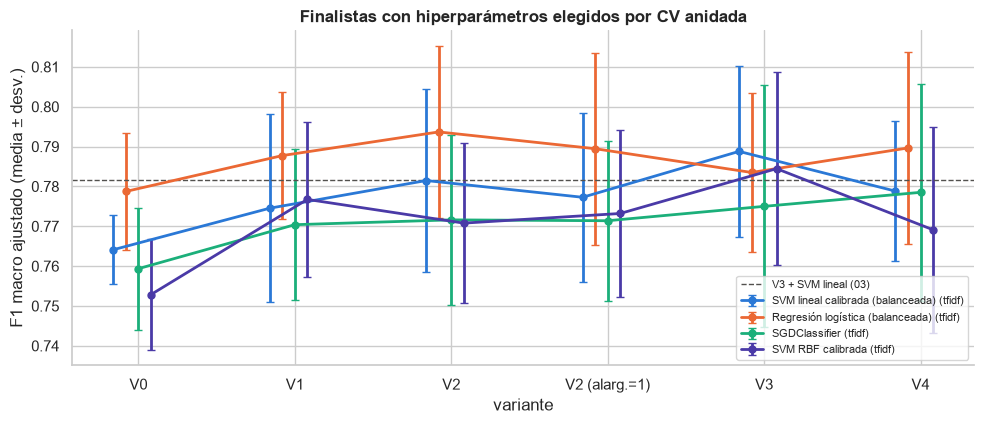

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.4))
variants = list(pp.VARIANTS)
x = np.arange(len(variants))
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7", "#e34948"]
for k, (clf, feats) in enumerate(FINALISTS):
    ids = [md.model_name(v, clf, feats, "nested") for v in variants]
    means = [RESULTS[i]["cv"]["tuned"]["F1_macro"].mean() for i in ids]
    stds = [RESULTS[i]["cv"]["tuned"]["F1_macro"].std() for i in ids]
    ax.errorbar(x + (k - 2) * 0.08, means, yerr=stds, fmt="o-", capsize=3, lw=2, ms=5, color=palette[k % 5],
                label=f"{md.CLASSIFIER_NAMES[clf]} ({feats})")
ax.axhline(RESULTS[REF]["cv"]["tuned"]["F1_macro"].mean(), color="#52514e", ls="--", lw=1, label="V3 + SVM lineal (03)")
ax.set(xticks=x, xticklabels=variants, xlabel="variante", ylabel="F1 macro ajustado (media ± desv.)",
       title="Finalistas con hiperparámetros elegidos por CV anidada")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
savefig(fig, "finalists_nested")
plt.show()

**Interpretación:**
- **Finalistas:** en V3 ningún modelo empató con la referencia, así que se tomaron los 4 mejores por media: SVM lineal, regresión logística, SGD y SVM RBF. NB-SVM quedó fuera por 0.0005, una diferencia dentro del ruido; si interesa por diversidad, conviene incluirla en el ensamble.
- **La regresión logística ajustada es la mejor familia.** La CV interna elige casi siempre **elasticnet (l1_ratio 0.5) con C = 3–10**.
  - V2: **0.794 ± 0.022**, mejor que la referencia en los 5 folds (+0.012 ± 0.009).
  - V1: 0.788 ± 0.016 (+0.006 ± 0.004, 5/5, "mejor").
  - V4: 0.790, V2 (alarg.=1): 0.790, V3: 0.784, V0: 0.779 (empates).
- **La SVM lineal ajustada en V3 da 0.789 ± 0.022**, "mejor" por muy poco (+0.0071 ± 0.0070). Su modelo final usa C=1, el mismo que la referencia: la ganancia viene de adaptar C en cada fold (0.3–3). Es una diferencia frágil.
- **La SVM RBF** (C = 3–10) llega a 0.785 en V3, empatada, pero en el resto de variantes es "peor". Además cuesta 105–131 s por CV anidada y ocupa 18–20 MB. **No compensa** frente a los lineales.
- **SGD** (`log_loss`, alpha 1e-4–3e-4) queda en 0.759–0.779.
- **Entre las mejores configuraciones anidadas las diferencias son del orden del ruido.** La regresión logística en V2, V4 y V2 (alarg.=1) y la SVM en V3 están todas a ≤ 0.006 entre sí. La variante vuelve a importar poco, salvo V0.
- Las 24 CV anidadas tardaron unos 40 minutos.

## 6. Naive Bayes y árboles en las 6 variantes (pregunta P8)

En el `02` y el `03`, la restauración de palabras (V3) y los lemas (V4) no aportaban, quizá porque los n-gramas de caracteres ya absorbían la fragmentación. Aquí NB y los árboles trabajan **solo con palabras**: si la restauración o los lemas ayudan en algún sitio, debería verse en ellos. Usamos la configuración por defecto (los árboles, con su mejor entrada del cribado) en las 6 variantes y medimos dos diferencias pareadas:
- **V3 − V2:** efecto de la restauración;
- **V4 − V3:** efecto de añadir lemas.

In [12]:
P8_MODELS = [("mnb", "word", {}, None), ("bnb", "word", {}, None), ("cnb", "word", {}, None)] + [
    (c, RESULTS[i]["features"], RESULTS[i]["model"].clf_params or {}, RESULTS[i]["tag"]) for c, i in best_tree_input.items()]
t0 = time.perf_counter()
jobs = [(cfg, variant) for cfg in P8_MODELS for variant in pp.VARIANTS]
for k, ((clf, feats, params, tag), variant) in enumerate(jobs, 1):
    run(variant, clf, feats, params, tag, stage="cribado" if variant in ("V1", "V3") else "6 variantes",
        step=f"{k}/{len(jobs)}")
print(f"Hecho en {time.perf_counter() - t0:.0f} s")


def paired(a, b):
    d = RESULTS[a]["cv"]["tuned"]["F1_macro"] - RESULTS[b]["cv"]["tuned"]["F1_macro"]
    return f"{d.mean():+.4f} ± {d.std():.4f} ({int((d > 0).sum())}/5)"


rows = []
for clf, feats, params, tag in P8_MODELS + [("linsvm", "tfidf", {}, None)]:
    ids = {v: md.model_name(v, clf, feats, tag) for v in pp.VARIANTS}
    if clf == "linsvm":
        for v in pp.VARIANTS:
            run(v, clf, stage="6 variantes", step=f"linsvm {v}")
    row = {"modelo": ids["V3"].replace("V3__", ""), "usa caracteres": clf == "linsvm"}
    row.update({v: round(RESULTS[i]["cv"]["tuned"]["F1_macro"].mean(), 4) for v, i in ids.items()})
    row["V3 − V2 (restauración)"] = paired(ids["V3"], ids["V2"])
    row["V4 − V3 (lemas)"] = paired(ids["V4"], ids["V3"])
    row["V1 − V0 (limpieza)"] = paired(ids["V1"], ids["V0"])
    rows.append(row)
p8 = pd.DataFrame(rows).set_index("modelo")
display(p8)

[1/42] V0__mnb__word (CV) ... 

F1 macro 0.7147 ± 0.0280 | 1.2 s | total transcurrido 44:53


[2/42] V1__mnb__word: ya calculado


[3/42] V2__mnb__word (CV) ... 

F1 macro 0.7353 ± 0.0207 | 1.2 s | total transcurrido 44:54


...

F1 macro 0.7782 ± 0.0222 | 2.0 s | total transcurrido 46:16


[linsvm V3] V3__linsvm: ya calculado


[linsvm V4] V4__linsvm (CV) ... 

F1 macro 0.7807 ± 0.0202 | 2.2 s | total transcurrido 46:18


,usa caracteres,V0,V1,V2,V2 (alarg.=1),V3,V4,V3 − V2 (restauración),V4 − V3 (lemas),V1 − V0 (limpieza)
modelo,,,,,,,,,,
mnb__word,False,0.7147,0.7365,0.7353,0.7352,0.7375,0.7436,+0.0023 ± 0.0077 (3/5),+0.0060 ± 0.0063 (3/5),+0.0219 ± 0.0110 (5/5)
bnb__word,False,0.2109,0.3728,0.3871,0.3897,0.4065,0.3443,+0.0194 ± 0.0140 (5/5),-0.0622 ± 0.0119 (0/5),+0.1619 ± 0.0162 (5/5)
cnb__word,False,0.7128,0.7399,0.7368,0.7373,0.7322,0.7461,-0.0046 ± 0.0090 (1/5),+0.0140 ± 0.0078 (5/5),+0.0271 ± 0.0147 (5/5)
rf__word__k2000,False,0.6933,0.7476,0.7400,0.7438,0.7489,0.7427,+0.0089 ± 0.0144 (4/5),-0.0063 ± 0.0080 (2/5),+0.0543 ± 0.0229 (5/5)
et__word__k2000,False,0.7137,0.7554,0.7532,0.7497,0.7670,0.7597,+0.0138 ± 0.0077 (5/5),-0.0073 ± 0.0091 (1/5),+0.0418 ± 0.0220 (5/5)
xgb__word__k500,False,0.7018,0.7409,0.7395,0.7366,0.7494,0.7487,+0.0099 ± 0.0106 (4/5),-0.0007 ± 0.0074 (2/5),+0.0391 ± 0.0080 (5/5)
lgbm__word__k2000,False,0.6962,0.7423,0.7416,0.7340,0.7425,0.7455,+0.0009 ± 0.0127 (3/5),+0.0030 ± 0.0152 (2/5),+0.0460 ± 0.0216 (5/5)
linsvm,True,0.7663,0.7756,0.7776,0.7782,0.7817,0.7807,+0.0041 ± 0.0051 (4/5),-0.0010 ± 0.0072 (2/5),+0.0093 ± 0.0159 (4/5)


**Interpretación (P8):**
- **Sin n-gramas de caracteres, la limpieza (V1 − V0) pesa mucho más:** entre +0.022 y +0.054 en los 5 folds en todos los modelos, frente a +0.009 en la SVM lineal.
- **La restauración (V3 − V2) ayuda en los árboles:**
  - ExtraTrees +0.014 ± 0.008 (5/5, consistente);
  - XGBoost +0.010 ± 0.011 y RF +0.009 ± 0.014 (positivos, pero dentro del ruido);
  - NB y LightGBM: ≈ 0.
- **Los lemas (V4 − V3) ayudan en Naive Bayes:** Complement NB +0.014 ± 0.008 (5/5) y Multinomial +0.006 ± 0.006. En los árboles son neutros o negativos (ExtraTrees −0.007, RF −0.006).
- Bernoulli NB sube y baja mucho, pero no es un modelo útil (F1 ≈ 0.4).

**Respuesta a P8:** sí, cuando no hay caracteres que absorban la fragmentación, la restauración y los lemas aportan algo en algunos modelos (ExtraTrees y CNB). Aun así, ninguno de esos modelos alcanza a los lineales con caracteres. La pregunta se reabrirá con los embeddings del `05`.

## 7. Diversidad: ¿qué modelos se complementan?

Un ensamble mejora si sus miembros **se equivocan en tuits distintos**. Tomamos el mejor modelo de cada clasificador en V3 (la versión anidada de los finalistas) y, con sus decisiones OOF (umbral elegido en los otros folds y jerarquía), calculamos dos cosas:
- **Correlación de errores:** correlación entre los vectores "se equivoca / acierta" de dos modelos, sobre las 1731 × 3 decisiones. 1 = fallan exactamente en lo mismo; 0 = fallan en sitios independientes.
- **% de tuits donde A acierta las tres etiquetas y B no:** cuánto puede aportar A a B.

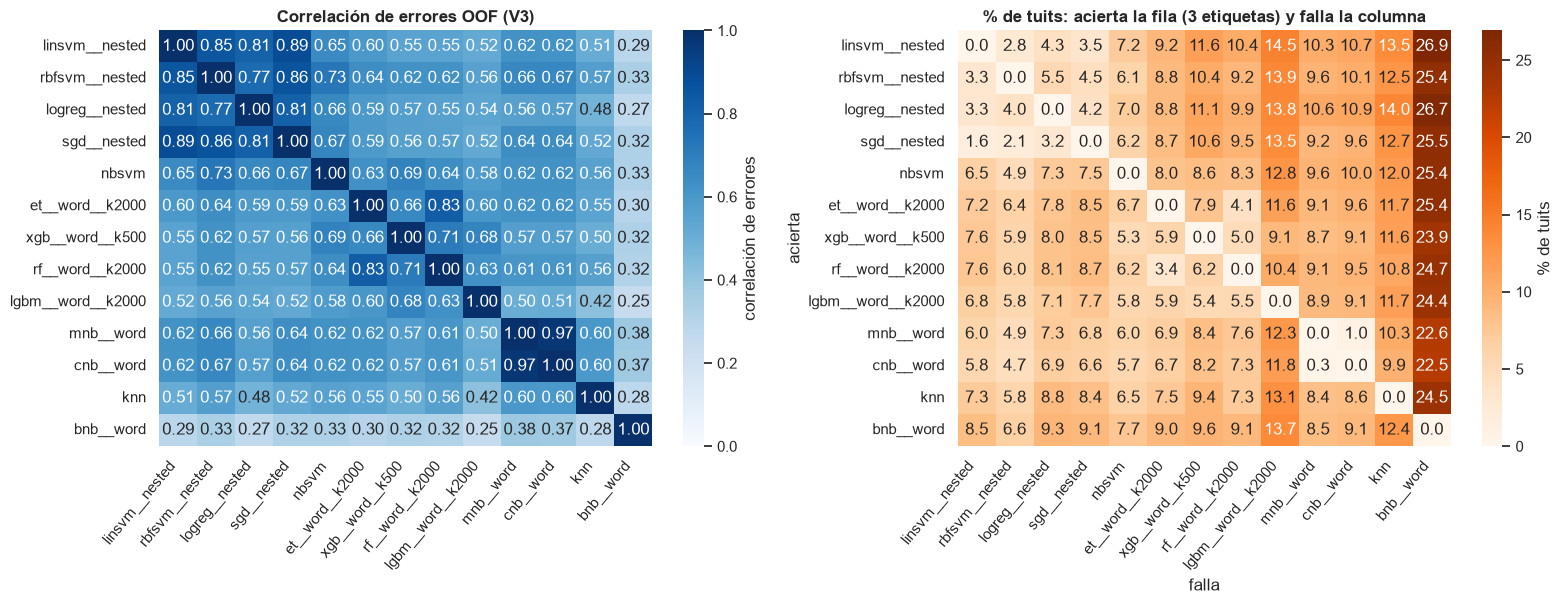

,familia,macro,desv.,veredicto
model_id,,,,
V3__linsvm__nested,lineal,0.7888,0.0215,mejor
V3__rbfsvm__nested,kernel,0.7845,0.0242,empate
V3__logreg__nested,lineal,0.7835,0.0199,empate
V3__sgd__nested,lineal,0.7750,0.0303,empate
V3__nbsvm,lineal,0.7709,0.0153,peor
V3__et__word__k2000,árboles,0.7670,0.0216,peor
V3__xgb__word__k500,boosting,0.7494,0.0246,peor
V3__rf__word__k2000,árboles,0.7489,0.0314,peor
V3__lgbm__word__k2000,boosting,0.7425,0.0173,peor


In [13]:
def crossfit_pred(oof):
    """Decisiones OOF con el umbral elegido en los otros folds y jerarquía (como en la evaluación)."""
    pred = np.zeros_like(Y)
    for k in sorted(folds.unique()):
        val = (folds == k).to_numpy()
        pred[val] = md.apply_decision(oof[val], md.best_thresholds(Y[~val], oof[~val]), hierarchy=True)
    return pred


candidates = {}
for mid, r in RESULTS.items():
    if r["variant"] != "V3" or r["stage"] == "rasgos":
        continue
    c = r["classifier"]
    score = r["cv"]["tuned"]["F1_macro"].mean()
    if c not in candidates or score > RESULTS[candidates[c]]["cv"]["tuned"]["F1_macro"].mean():
        candidates[c] = mid
ens_ids = sorted(candidates.values(), key=lambda i: -RESULTS[i]["cv"]["tuned"]["F1_macro"].mean())
preds = {i: crossfit_pred(RESULTS[i]["cv"]["oof"]) for i in ens_ids}
errors = pd.DataFrame({i.replace("V3__", ""): (preds[i] != Y).ravel().astype(int) for i in ens_ids})
tweet_ok = {i.replace("V3__", ""): (preds[i] == Y).all(axis=1) for i in ens_ids}
err_corr = errors.corr()
complement = pd.DataFrame({a: {b: 100 * np.mean(tweet_ok[a] & ~tweet_ok[b]) for b in tweet_ok} for a in tweet_ok}).T

fig, axes = plt.subplots(1, 2, figsize=(16, 6.2))
sns.heatmap(err_corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[0], cbar_kws={"label": "correlación de errores"})
axes[0].set_title("Correlación de errores OOF (V3)")
sns.heatmap(complement, annot=True, fmt=".1f", cmap="Oranges", ax=axes[1], cbar_kws={"label": "% de tuits"})
axes[1].set(title="% de tuits: acierta la fila (3 etiquetas) y falla la columna", xlabel="falla", ylabel="acierta")
for ax in axes:
    ax.set_xticklabels(ax.get_xticklabels(), rotation=50, ha="right")
fig.tight_layout()
savefig(fig, "error_diversity")
plt.show()
display(summarize(ens_ids)[["familia", "macro", "desv.", "veredicto"]])

**Interpretación:**
- **Los lineales se equivocan casi en lo mismo:** la correlación de errores entre las versiones anidadas de SVM, regresión logística, SGD y RBF va de 0.77 a 0.89. Combinarlos aportará poco.
- **Árboles y boosting se equivocan en otros tuits:** correlación de 0.52–0.64 con los lineales. Aciertan las tres etiquetas en el 6.8–7.6% de los tuits en los que la SVM ajustada falla, frente al 3.3% de la regresión logística.
- **NB-SVM** (0.65–0.73) y **Multinomial NB** (0.56–0.66) también aportan algo de diversidad. Multinomial y Complement NB son casi el mismo modelo (0.97).
- Bernoulli NB y kNN tienen correlaciones bajas, pero porque fallan mucho más, no porque complementen.

**Candidatos para el ensamble:**
- el núcleo lineal: regresión logística ajustada (V2) y SVM lineal ajustada (V3);
- los complementos diversos: ExtraTrees chi2-2000, XGBoost chi2-500 o LightGBM chi2-2000, NB-SVM y Multinomial NB.

La diversidad solo sirve si el ensamble sabe ponderar: los árboles aciertan donde fallan los lineales, pero también fallan más en general (por ejemplo, LightGBM falla en el 14.5% de los tuits en los que la SVM acierta).

## 8. Guardado (contrato para los notebooks 05–07)

- **Todos los modelos evaluados** se añaden a `models/registry.csv`, con su familia, hiperparámetros (`params`), métricas, umbrales, si sus probabilidades están calibradas, tiempo y tamaño. Los que ya registró el `03` (`V1__linsvm`, `V3__linsvm`, `V1__logreg`, `V3__logreg`) no se duplican.
- **Sus probabilidades OOF y de test** se añaden a `models/oof_predictions.parquet` y `models/test_predictions.parquet`, con el formato común `model_id, id, fold, p_HS, p_TR, p_AG, calibrated` (y las etiquetas `HS, TR, AG` en test). El `07` las usará para ensamblar.
- **Se guarda el modelo completo** (`.joblib` + `.json`) de los **finalistas en las 6 variantes** y del **mejor modelo de cada clasificador en V3**. El resto queda registrado con `saved = False`: sus predicciones están disponibles y se pueden reentrenar con `run()`.

In [14]:
already_in_03 = {f"{v}__{c}" for v in ("V0", "V1", "V2", "V2-alarg1", "V3", "V4") for c in ("logreg", "linsvm", "cnb")}
to_save = set(nested_ids) | set(candidates.values())
rows, oof_frames, test_frames, saved_paths = [], [], [], []
for mid, r in RESULTS.items():
    if mid in already_in_03:
        continue
    model = r["model"]
    calibrated = r["classifier"] in md.CALIBRATED
    saved = mid in to_save
    if saved:
        cv = r["cv"]
        meta = {"notebook": "04", "stage": r["stage"],
                "cv": {s: {m: {"mean": float(cv[s][m].mean()), "std": float(cv[s][m].std())} for m in cv[s].columns}
                       for s in ("at_05", "tuned")},
                "cv_folds_file": "data/processed/folds.csv", "n_train": len(train),
                "thresholds_source": "F1 máximo sobre todas las OOF de la CV",
                "grid": r["grid"], "params_per_fold": cv.get("params_per_fold")}
        saved_paths.append(md.save_model(model, mid, meta))
    rows.append(md.registry_row(mid, model, r["cv"], notebook="04", saved=saved, size_mb=r["size_mb"]))
    oof_frames.append(md.prediction_frame(mid, train["id"], r["cv"]["oof"], fold=folds, calibrated=calibrated))
    test_frames.append(md.prediction_frame(mid, test["id"], r["test_proba"], pred=r["test_pred"], calibrated=calibrated))

registry = md.update_registry(rows)
oof_all = md.update_predictions(oof_frames, md.OOF_PATH)
test_all = md.update_predictions(test_frames, md.TEST_PRED_PATH)
print(f"Registro: {len(registry)} modelos ({(registry['notebook'] == '04').sum()} del 04) | "
      f"modelos guardados en este notebook: {len(saved_paths)} | "
      f"predicciones: {oof_all['model_id'].nunique()} modelos en OOF y {test_all['model_id'].nunique()} en test")
display(registry.head(15)[["model_id", "family", "params", "F1_macro", "F1_macro_std", "F1_micro", "proba_calibrated",
                           "size_mb", "saved", "notebook"]])

# Comprobación del contrato: un modelo guardado, cargado desde disco, reproduce sus predicciones de test
check_id = sorted(nested_ids)[0]
reloaded = md.load_model(check_id)
same = np.allclose(reloaded.predict_proba(test["text"]), RESULTS[check_id]["test_proba"])
print(f"{check_id}: ¿predicciones idénticas tras cargar? {same} | API: {type(reloaded).__name__}.predict -> "
      f"{reloaded.predict(test['text'].head(3)).tolist()}")

Registro: 126 modelos (108 del 04) | modelos guardados en este notebook: 33 | predicciones: 126 modelos en OOF y 126 en test


,model_id,family,params,F1_macro,F1_macro_std,F1_micro,proba_calibrated,size_mb,saved,notebook
0,V2__logreg__nested,lineal,"{""C"": 10.0, ""l1_ratio"": 0.5}",0.7937,0.0216,0.7897,False,0.52,True,04
1,V4__logreg__nested,lineal,"{""C"": 10.0, ""l1_ratio"": 0.5}",0.7896,0.0240,0.7855,False,0.74,True,04
2,V2-alarg1__logreg__nested,lineal,"{""C"": 10.0, ""l1_ratio"": 0.5}",0.7895,0.0241,0.7852,False,0.52,True,04
3,V3__linsvm__nested,lineal,"{""C"": 1.0}",0.7888,0.0215,0.7849,True,2.05,True,04
4,V1__logreg__nested,lineal,"{""C"": 3.0, ""l1_ratio"": 0.5}",0.7877,0.0159,0.7837,False,0.42,True,04
5,V3__rbfsvm__nested,kernel,"{""C"": 10.0}",0.7845,0.0242,0.7826,True,18.19,True,04
6,V3__logreg__nested,lineal,"{""C"": 3.0, ""l1_ratio"": 0.5}",0.7835,0.0199,0.7799,False,0.42,True,04
7,V3__linsvm,lineal,{},0.7817,0.0160,0.7781,True,2.05,True,03
8,V2__linsvm__nested,lineal,"{""C"": 1.0}",0.7815,0.0230,0.7780,True,2.07,True,04
9,V4__linsvm,lineal,{},0.7807,0.0202,0.7771,True,2.87,True,03


V0__linsvm__nested: ¿predicciones idénticas tras cargar? True | API: TweetToxicClassifier.predict -> [[0, 0, 0], [1, 1, 1], [0, 0, 0]]


## 9. Conclusiones

| Pregunta | Respuesta (F1 macro ajustado, 5 folds; Δ pareada frente a V3 + SVM lineal = 0.782 ± 0.016) |
|---|---|
| ¿Mejor modelo? | **Regresión logística elasticnet ajustada por CV anidada**: V2 0.794 ± 0.022 (+0.012 ± 0.009, 5/5) y V1 0.788 ± 0.016 (+0.006 ± 0.004, 5/5). V4 y V2 (alarg.=1) empatan (0.790) |
| ¿Mejora la SVM lineal al ajustarla? | Muy poco: 0.789 en V3 ("mejor" por +0.0071 ± 0.0070). El modelo final vuelve a C=1 |
| ¿Kernel RBF? | Empata en V3 (0.785) y es "peor" en las demás variantes; unas 10–20 veces más lenta y 9 veces más grande. No compensa |
| ¿Árboles y boosting? | Mejor caso ExtraTrees chi2-2000: 0.767 (−0.015). chi2 > SVD. **Útiles solo por diversidad** (correlación de errores 0.52–0.64) |
| ¿Naive Bayes y kNN? | Multinomial y Complement ≈ 0.73–0.75; Bernoulli inservible (0.41); kNN 0.73 |
| ¿Rasgos hechos a mano? | No en los lineales (empate, ligeramente negativo). Ayudan a XGBoost y LightGBM en V1 (+0.009 y +0.015); en V3, empate |
| ¿P8: restauración y lemas sin caracteres? | Algo: la restauración ayuda a ExtraTrees (+0.014, 5/5) y los lemas a CNB (+0.014, 5/5) |

**Familias que valen la pena:** las lineales con hiperparámetros ajustados (regresión logística elasticnet y SVM lineal). Los árboles y el boosting con chi2, junto con NB-SVM y Multinomial NB, solo como complementos de un ensamble.

**No valen la pena:** Bernoulli NB, kNN y SVM RBF (por coste), y los árboles con entrada SVD.

**Para el ensamble del `07`:**
- núcleo: `V2__logreg__nested`, `V1__logreg__nested` y `V3__linsvm__nested`;
- diversidad: `V3__et__word__k2000`, `V3__xgb__word__k500` o `V3__lgbm__word__k2000`, `V3__nbsvm` y `V3__mnb__word`.

Sus predicciones OOF y de test ya están en los parquet compartidos.

**Límites:**
- Con 1731 tuits, la desviación entre folds es de ≈0.02. Las diferencias entre las mejores configuraciones anidadas (≤ 0.006) no son significativas.
- El criterio "mejor/peor" (|Δ| frente a su desviación con 5 folds) es orientativo. Por ejemplo, la SVM lineal ajustada es "mejor" por 0.0001.
- Las rejillas son pequeñas. La regresión logística elige con frecuencia el C mayor de elasticnet (10), así que quizá convenga ampliar hacia C mayores.
- Las probabilidades solo están calibradas en las SVM. Para promediar modelos en el ensamble hará falta calibrar, o usar rangos o *stacking*.
- Las etiquetas de AG siguen teniendo el artefacto H3.